# Attention U-Net for SEM / Wafer Defect Segmentation — Dataset 1

This notebook is configured specifically for **`SEM wafer dataset-Folder- 1.coco`** and trains a **binary semantic-segmentation** model from its Roboflow COCO export with `train`, `valid`, and `test` folders. It uses Attention U-Net, AdamW, and creates **two augmented versions per training image** (the effective training set is 3×: original + 2 random augmentations).

## Outputs

- Training/validation loss and F1 curves
- Pixel-level confusion matrix for the test split
- Train/Validation/Test comparison table: Precision, Recall, Accuracy, F1 and F2
- Example image / ground-truth / prediction panels
- Saved best model and CSV history/metrics

> **Important:** An F1 score of 85% is a training target, not something code can honestly guarantee. The final score depends on annotation quality, split difficulty, image count, and class imbalance. This notebook avoids inventing results and prints the scores actually measured from your data.

### Dataset 1 configuration

- Expected images: **26 train / 7 validation / 4 test**
- Maximum epochs: **140** with early stopping after **25** unimproved epochs
- Batch size: **4**
- Effective training set per epoch: original images + two independently augmented versions


## Kaggle step 1 — Create the notebook and attach Dataset 1

1. Upload the complete folder **`SEM wafer dataset-Folder- 1.coco`** as a Kaggle Dataset. Keep `train`, `valid`, and `test` inside it.
2. Create a new Kaggle Notebook and select **Add Input** → the uploaded Dataset 1.
3. In **Settings**, choose a GPU accelerator (T4 is sufficient).
4. Import this `.ipynb` and choose **Run All**.

This notebook searches `/kaggle/input` for the attached folder using both the original folder label and Kaggle's normalized folder naming. It also checks the expected split counts before training, preventing accidental use of Dataset 1, 2, or 3 interchangeably.


In [4]:
# Install only the packages that may be absent from the Kaggle image.
!pip install -q pycocotools albumentations


In [5]:
import os, json, random, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from torch.optim.lr_scheduler import ReduceLROnPlateau
import albumentations as A
from pycocotools import mask as mask_utils

warnings.filterwarnings('ignore')

DATASET_NUMBER = 1
DATASET_FOLDER_HINT = 'SEM wafer dataset-Folder- 1.coco'
EXPECTED_COUNTS = {'train': 26, 'valid': 7, 'test': 4}
SEED = 42
IMG_SIZE = 256       # Try 384/512 only if defects are tiny and GPU memory permits.
BATCH_SIZE = 4
EPOCHS = 140    # Maximum; early stopping normally ends training sooner.
LEARNING_RATE = 3e-4
WEIGHT_DECAY = 1e-4
NUM_WORKERS = 2
PATIENCE = 25
TARGET_F1 = 0.85
THRESHOLD_GRID = np.arange(0.20, 0.81, 0.05)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
OUTPUT_DIR = Path('/kaggle/working/attention_unet_dataset_1_outputs')
OUTPUT_DIR.mkdir(exist_ok=True)

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.benchmark = True
print('Dataset:', DATASET_FOLDER_HINT)
print('Device:', DEVICE)
print(f'Max epochs={EPOCHS}, batch size={BATCH_SIZE}, patience={PATIENCE}')


Dataset: SEM wafer dataset-Folder- 1.coco
Device: cuda
Max epochs=140, batch size=4, patience=25


## Kaggle step 2 — Locate and validate the COCO dataset

This checks filenames against COCO `images` records. Empty-mask images are allowed and are useful negative examples. All annotated object categories are merged into one foreground class, which matches binary SEM-defect segmentation.


In [6]:
def normalized_name(text):
    return ''.join(ch.lower() for ch in text if ch.isalnum())

def find_dataset_root(search_root='/kaggle/input'):
    candidates = []
    for annotation_file in Path(search_root).rglob('_annotations.coco.json'):
        root = annotation_file.parent.parent
        if all((root / split / '_annotations.coco.json').is_file()
               for split in ('train', 'valid', 'test')):
            candidates.append(root)
    candidates = sorted(set(candidates))
    if not candidates:
        raise FileNotFoundError(
            'No COCO dataset with train/valid/test was found under /kaggle/input. '
            'Attach the complete Roboflow export first.'
        )

    target = normalized_name(DATASET_FOLDER_HINT)
    matches = [p for p in candidates if target in normalized_name(str(p))]
    if not matches:
        # Kaggle may rename the uploaded dataset. Use split counts as a safe fallback.
        count_matches = []
        for root in candidates:
            observed = {}
            for split in ('train', 'valid', 'test'):
                with open(root / split / '_annotations.coco.json', encoding='utf-8') as f:
                    observed[split] = len(json.load(f).get('images', []))
            if observed == EXPECTED_COUNTS:
                count_matches.append(root)
        matches = count_matches

    if len(matches) != 1:
        found = '\n'.join(str(p) for p in candidates)
        raise RuntimeError(
            f'Could not uniquely identify {DATASET_FOLDER_HINT}. Matches={{len(matches)}}. '
            f'Found these COCO roots:\n{{found}}'
        )
    return matches[0]

DATA_ROOT = find_dataset_root()
print('Selected dataset root:', DATA_ROOT)

def inspect_split(split):
    split_dir = DATA_ROOT / split
    with open(split_dir / '_annotations.coco.json', encoding='utf-8') as f:
        coco = json.load(f)
    files_on_disk = {p.name for p in split_dir.iterdir()
                     if p.suffix.lower() in {'.jpg', '.jpeg', '.png', '.tif', '.tiff'} and p.is_file()}
    listed = {x['file_name'] for x in coco['images']}
    missing = sorted(listed - files_on_disk)
    return {
        'Split': split.title(), 'COCO images': len(listed),
        'Expected images': EXPECTED_COUNTS[split], 'Image files': len(files_on_disk),
        'Annotations': len(coco.get('annotations', [])), 'Missing files': len(missing)
    }

inspection = pd.DataFrame([inspect_split(s) for s in ('train','valid','test')])
display(inspection)
if not (inspection['COCO images'].to_numpy() == inspection['Expected images'].to_numpy()).all():
    raise ValueError('Split counts do not match this notebook. Attach the correct dataset or update EXPECTED_COUNTS.')
if inspection['Missing files'].sum() != 0:
    raise FileNotFoundError('Some images referenced by COCO JSON are missing from their split folders.')
print('Dataset identity and file checks passed.')


Selected dataset root: /kaggle/input/datasets/sarthakjadhav07/sem-dataset-1/SEM wafer dataset-Folder- 1.coco


,Split,COCO images,Expected images,Image files,Annotations,Missing files
0,Train,26,26,26,38,0
1,Valid,7,7,7,9,0
2,Test,4,4,4,5,0


Dataset identity and file checks passed.


## Kaggle step 3 — Build masks and augment the training data

COCO polygon and RLE annotations are decoded into a single binary mask. Geometry transforms are applied identically to image and mask. The training dataset has a multiplier of 3: index 0 is the original-style sample, while indexes 1 and 2 use independent random augmentation pipelines.


In [7]:
train_transform = A.Compose([
    A.Resize(IMG_SIZE, IMG_SIZE),
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.RandomRotate90(p=0.5),
    A.ShiftScaleRotate(shift_limit=0.08, scale_limit=0.12, rotate_limit=25,
                       border_mode=0, p=0.6),
    A.OneOf([A.RandomBrightnessContrast(p=1), A.CLAHE(p=1), A.RandomGamma(p=1)], p=0.5),
    A.OneOf([A.GaussNoise(p=1), A.GaussianBlur(blur_limit=(3,5), p=1)], p=0.25),
])
eval_transform = A.Compose([A.Resize(IMG_SIZE, IMG_SIZE)])

class COCOSegmentationDataset(Dataset):
    def __init__(self, split, transform, augmentation_copies=0):
        self.split_dir = DATA_ROOT / split
        with open(self.split_dir / '_annotations.coco.json', encoding='utf-8') as f:
            coco = json.load(f)
        self.images = sorted(coco['images'], key=lambda x: x['id'])
        self.anns_by_image = {}
        for ann in coco.get('annotations', []):
            self.anns_by_image.setdefault(ann['image_id'], []).append(ann)
        self.transform = transform
        self.multiplier = 1 + augmentation_copies

    def __len__(self): return len(self.images) * self.multiplier

    @staticmethod
    def decode_annotation(ann, height, width):
        seg = ann.get('segmentation')
        if not seg: return np.zeros((height, width), dtype=np.uint8)
        if isinstance(seg, list):
            rles = mask_utils.frPyObjects(seg, height, width)
            decoded = mask_utils.decode(rles)
        elif isinstance(seg, dict) and isinstance(seg.get('counts'), list):
            decoded = mask_utils.decode(mask_utils.frPyObjects(seg, height, width))
        else:
            decoded = mask_utils.decode(seg)
        if decoded.ndim == 3: decoded = decoded.max(axis=2)
        return decoded.astype(np.uint8)

    def __getitem__(self, index):
        info = self.images[index % len(self.images)]
        path = self.split_dir / info['file_name']
        image = np.asarray(Image.open(path).convert('RGB'))
        h, w = image.shape[:2]
        mask = np.zeros((h, w), dtype=np.uint8)
        for ann in self.anns_by_image.get(info['id'], []):
            mask = np.maximum(mask, self.decode_annotation(ann, h, w))
        transformed = self.transform(image=image, mask=mask)
        image = transformed['image'].astype(np.float32) / 255.0
        mask = (transformed['mask'] > 0).astype(np.float32)
        image = torch.from_numpy(image.transpose(2,0,1))
        mask = torch.from_numpy(mask[None, ...])
        return image, mask, info['file_name']

train_ds = COCOSegmentationDataset('train', train_transform, augmentation_copies=2)
train_eval_ds = COCOSegmentationDataset('train', eval_transform)
valid_ds = COCOSegmentationDataset('valid', eval_transform)
test_ds = COCOSegmentationDataset('test', eval_transform)

loader_kwargs = dict(batch_size=BATCH_SIZE, num_workers=NUM_WORKERS,
                     pin_memory=torch.cuda.is_available())
train_loader = DataLoader(train_ds, shuffle=True, **loader_kwargs)
train_eval_loader = DataLoader(train_eval_ds, shuffle=False, **loader_kwargs)
valid_loader = DataLoader(valid_ds, shuffle=False, **loader_kwargs)
test_loader = DataLoader(test_ds, shuffle=False, **loader_kwargs)
print(f'Train: {len(train_eval_ds)} originals → {len(train_ds)} samples/epoch (original + 2 augmented)')
print(f'Validation: {len(valid_ds)} | Test: {len(test_ds)}')


Train: 26 originals → 78 samples/epoch (original + 2 augmented)
Validation: 7 | Test: 4


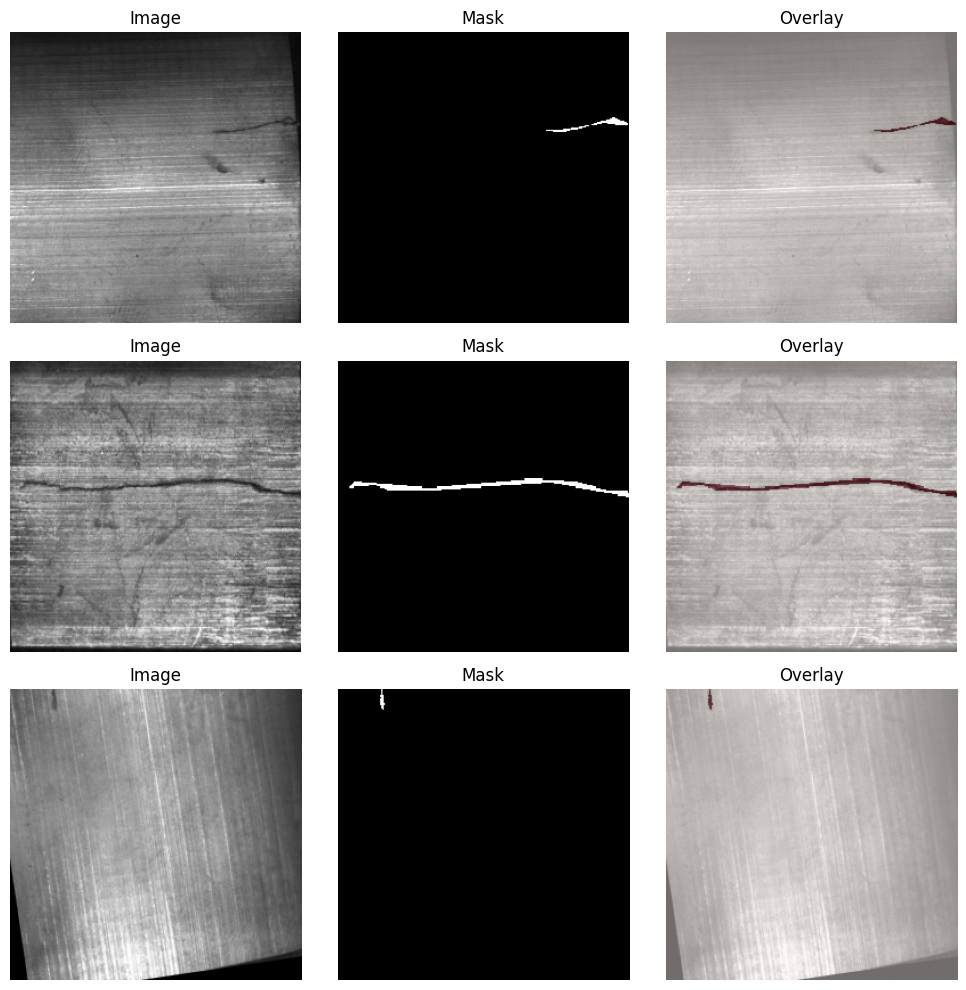

In [8]:
# Visual mask sanity check — run this before training.
fig, axes = plt.subplots(3, 3, figsize=(10, 10))
for row in range(3):
    image, mask, name = train_ds[row]
    img = image.permute(1,2,0).numpy()
    m = mask.squeeze().numpy()
    axes[row,0].imshow(img); axes[row,0].set_title('Image')
    axes[row,1].imshow(m, cmap='gray'); axes[row,1].set_title('Mask')
    axes[row,2].imshow(img); axes[row,2].imshow(m, cmap='Reds', alpha=0.45)
    axes[row,2].set_title('Overlay')
    for ax in axes[row]: ax.axis('off')
plt.tight_layout(); plt.show()


## Kaggle step 4 — Attention U-Net

The attention gates suppress irrelevant background features before each decoder skip connection. Group Normalization is used because this dataset is small and GPU batch sizes may be modest.


In [9]:
class ConvBlock(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        groups = min(8, out_ch)
        self.block = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False), nn.GroupNorm(groups, out_ch), nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False), nn.GroupNorm(groups, out_ch), nn.ReLU(inplace=True)
        )
    def forward(self, x): return self.block(x)

class AttentionGate(nn.Module):
    def __init__(self, gate_ch, skip_ch, inter_ch):
        super().__init__()
        self.gate = nn.Sequential(nn.Conv2d(gate_ch, inter_ch, 1, bias=False), nn.BatchNorm2d(inter_ch))
        self.skip = nn.Sequential(nn.Conv2d(skip_ch, inter_ch, 1, bias=False), nn.BatchNorm2d(inter_ch))
        self.psi = nn.Sequential(nn.ReLU(inplace=True), nn.Conv2d(inter_ch, 1, 1), nn.Sigmoid())
    def forward(self, gate, skip):
        return skip * self.psi(self.gate(gate) + self.skip(skip))

class UpAttentionBlock(nn.Module):
    def __init__(self, in_ch, skip_ch, out_ch):
        super().__init__()
        self.up = nn.ConvTranspose2d(in_ch, out_ch, 2, stride=2)
        self.att = AttentionGate(out_ch, skip_ch, max(out_ch // 2, 1))
        self.conv = ConvBlock(out_ch + skip_ch, out_ch)
    def forward(self, x, skip):
        x = self.up(x)
        skip = self.att(x, skip)
        return self.conv(torch.cat([x, skip], dim=1))

class AttentionUNet(nn.Module):
    def __init__(self, in_ch=3, out_ch=1, base=32):
        super().__init__()
        self.pool = nn.MaxPool2d(2)
        self.e1 = ConvBlock(in_ch, base)
        self.e2 = ConvBlock(base, base*2)
        self.e3 = ConvBlock(base*2, base*4)
        self.e4 = ConvBlock(base*4, base*8)
        self.bridge = ConvBlock(base*8, base*16)
        self.d4 = UpAttentionBlock(base*16, base*8, base*8)
        self.d3 = UpAttentionBlock(base*8, base*4, base*4)
        self.d2 = UpAttentionBlock(base*4, base*2, base*2)
        self.d1 = UpAttentionBlock(base*2, base, base)
        self.out = nn.Conv2d(base, out_ch, 1)
    def forward(self, x):
        e1 = self.e1(x); e2 = self.e2(self.pool(e1)); e3 = self.e3(self.pool(e2)); e4 = self.e4(self.pool(e3))
        b = self.bridge(self.pool(e4))
        return self.out(self.d1(self.d2(self.d3(self.d4(b,e4),e3),e2),e1))

model = AttentionUNet().to(DEVICE)
print(f'Parameters: {sum(p.numel() for p in model.parameters()):,}')


Parameters: 7,851,285


## Kaggle step 5 — Loss, AdamW, and training

`BCEWithLogits + Dice loss` balances pixel classification with region overlap. The best checkpoint is selected using validation F1 at threshold 0.5. Early stopping reduces overfitting on the small dataset.


In [10]:
bce = nn.BCEWithLogitsLoss()
def dice_loss(logits, targets, eps=1e-7):
    probs = torch.sigmoid(logits)
    dims = (1,2,3)
    intersection = (probs * targets).sum(dims)
    dice = (2*intersection + eps) / (probs.sum(dims) + targets.sum(dims) + eps)
    return 1 - dice.mean()

def combined_loss(logits, targets): return 0.5*bce(logits, targets) + 0.5*dice_loss(logits, targets)

def batch_counts(logits, targets, threshold=0.5):
    pred = torch.sigmoid(logits) >= threshold
    true = targets >= 0.5
    tp = (pred & true).sum().item(); fp = (pred & ~true).sum().item()
    fn = (~pred & true).sum().item(); tn = (~pred & ~true).sum().item()
    return tp, fp, fn, tn

def scores_from_counts(tp, fp, fn, tn, eps=1e-8):
    precision = tp/(tp+fp+eps); recall = tp/(tp+fn+eps); accuracy = (tp+tn)/(tp+fp+fn+tn+eps)
    f1 = 2*precision*recall/(precision+recall+eps)
    return precision, recall, accuracy, f1

optimizer = AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
scheduler = ReduceLROnPlateau(optimizer, mode='max', factor=0.5, patience=4)
scaler = torch.cuda.amp.GradScaler(enabled=torch.cuda.is_available())

history = {'train_loss':[], 'valid_loss':[], 'train_f1':[], 'valid_f1':[]}
best_f1, stale = -1, 0

for epoch in range(1, EPOCHS+1):
    model.train(); train_loss = 0; counts = np.zeros(4, dtype=np.float64)
    for images, masks, _ in train_loader:
        images, masks = images.to(DEVICE), masks.to(DEVICE)
        optimizer.zero_grad(set_to_none=True)
        with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):
            logits = model(images); loss = combined_loss(logits, masks)
        scaler.scale(loss).backward(); scaler.step(optimizer); scaler.update()
        train_loss += loss.item()*images.size(0); counts += batch_counts(logits.detach(), masks)
    train_loss /= len(train_loader.dataset)
    train_f1 = scores_from_counts(*counts)[3]

    model.eval(); valid_loss = 0; counts = np.zeros(4, dtype=np.float64)
    with torch.no_grad():
        for images, masks, _ in valid_loader:
            images, masks = images.to(DEVICE), masks.to(DEVICE)
            logits = model(images); loss = combined_loss(logits, masks)
            valid_loss += loss.item()*images.size(0); counts += batch_counts(logits, masks)
    valid_loss /= len(valid_loader.dataset)
    valid_f1 = scores_from_counts(*counts)[3]
    scheduler.step(valid_f1)
    for k,v in [('train_loss',train_loss),('valid_loss',valid_loss),('train_f1',train_f1),('valid_f1',valid_f1)]: history[k].append(v)

    print(f'Epoch {epoch:03d} | loss {train_loss:.4f}/{valid_loss:.4f} | F1 {train_f1:.4f}/{valid_f1:.4f}')
    if valid_f1 > best_f1 + 1e-4:
        best_f1, stale = valid_f1, 0
        torch.save(model.state_dict(), OUTPUT_DIR/'best_attention_unet.pth')
    else:
        stale += 1
        if stale >= PATIENCE:
            print('Early stopping.'); break

pd.DataFrame(history).to_csv(OUTPUT_DIR/'training_history.csv', index=False)
model.load_state_dict(torch.load(OUTPUT_DIR/'best_attention_unet.pth', map_location=DEVICE))
print(f'Best validation F1 at 0.5 threshold: {best_f1:.4f}')


Epoch 001 | loss 0.6357/0.5857 | F1 0.0085/0.0000
Epoch 002 | loss 0.5801/0.5753 | F1 0.0000/0.0000
Epoch 003 | loss 0.5714/0.5676 | F1 0.0000/0.0000
Epoch 004 | loss 0.5643/0.5612 | F1 0.0000/0.0000
Epoch 005 | loss 0.5580/0.5542 | F1 0.0000/0.0000
Epoch 006 | loss 0.5520/0.5492 | F1 0.0000/0.0000
Epoch 007 | loss 0.5470/0.5442 | F1 0.0000/0.0000
Epoch 008 | loss 0.5429/0.5392 | F1 0.0000/0.0000
Epoch 009 | loss 0.5400/0.5355 | F1 0.1124/0.3723
Epoch 010 | loss 0.5335/0.5346 | F1 0.4424/0.2584
Epoch 011 | loss 0.5311/0.5261 | F1 0.3377/0.5079
Epoch 012 | loss 0.5245/0.5177 | F1 0.4032/0.4251
Epoch 013 | loss 0.5213/0.5148 | F1 0.3977/0.5184
Epoch 014 | loss 0.5150/0.5129 | F1 0.4462/0.4505
Epoch 015 | loss 0.5143/0.5077 | F1 0.4007/0.3972
Epoch 016 | loss 0.5079/0.5005 | F1 0.4584/0.4682
Epoch 017 | loss 0.5059/0.4986 | F1 0.4336/0.5063
Epoch 018 | loss 0.5073/0.4972 | F1 0.4009/0.4357
Epoch 019 | loss 0.5018/0.4941 | F1 0.4369/0.4584
Epoch 020 | loss 0.4976/0.4955 | F1 0.4607/0.3695


## Kaggle step 6 — Loss and F1 graphs

The gap between training and validation curves is the main overfitting signal. If validation loss rises while training loss falls, increase augmentation/dropout, reduce model size, or stop earlier.


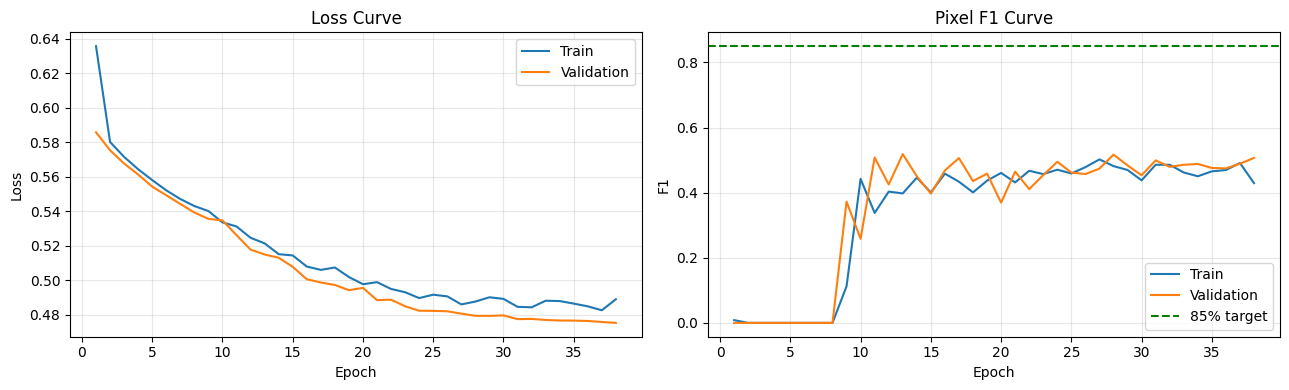

In [11]:
epochs_ran = range(1, len(history['train_loss'])+1)
fig, axes = plt.subplots(1, 2, figsize=(13,4))
axes[0].plot(epochs_ran, history['train_loss'], label='Train'); axes[0].plot(epochs_ran, history['valid_loss'], label='Validation')
axes[0].set(title='Loss Curve', xlabel='Epoch', ylabel='Loss'); axes[0].legend(); axes[0].grid(alpha=.3)
axes[1].plot(epochs_ran, history['train_f1'], label='Train'); axes[1].plot(epochs_ran, history['valid_f1'], label='Validation')
axes[1].axhline(TARGET_F1, color='green', ls='--', label='85% target')
axes[1].set(title='Pixel F1 Curve', xlabel='Epoch', ylabel='F1'); axes[1].legend(); axes[1].grid(alpha=.3)
plt.tight_layout(); plt.savefig(OUTPUT_DIR/'training_curves.png', dpi=180, bbox_inches='tight'); plt.show()


## Kaggle step 7 — Tune the threshold on validation only

A segmentation probability must be converted to foreground/background. We select the threshold that maximizes validation F1, then freeze it before evaluating the test set. This prevents test-set leakage.


In [12]:
@torch.no_grad()
def collect_probabilities(loader):
    model.eval(); probs, truths = [], []
    for images, masks, _ in loader:
        logits = model(images.to(DEVICE))
        probs.append(torch.sigmoid(logits).cpu().numpy().ravel())
        truths.append(masks.numpy().ravel().astype(np.uint8))
    return np.concatenate(probs), np.concatenate(truths)

valid_probs, valid_true = collect_probabilities(valid_loader)
threshold_rows = []
for threshold in THRESHOLD_GRID:
    pred = valid_probs >= threshold
    tp = np.sum(pred & (valid_true==1)); fp = np.sum(pred & (valid_true==0))
    fn = np.sum(~pred & (valid_true==1)); tn = np.sum(~pred & (valid_true==0))
    p,r,a,f1 = scores_from_counts(tp,fp,fn,tn)
    threshold_rows.append([threshold,p,r,a,f1])
threshold_df = pd.DataFrame(threshold_rows, columns=['Threshold','Precision','Recall','Accuracy','F1'])
BEST_THRESHOLD = float(threshold_df.loc[threshold_df.F1.idxmax(), 'Threshold'])
display(threshold_df.style.format('{:.4f}'))
print('Selected validation threshold:', BEST_THRESHOLD)


,Threshold,Precision,Recall,Accuracy,F1
0,0.2000,0.3432,0.7471,0.9945,0.4703
1,0.2500,0.3610,0.7150,0.9950,0.4797
2,0.3000,0.3811,0.6901,0.9954,0.4911
3,0.3500,0.4020,0.6727,0.9957,0.5033
4,0.4000,0.4178,0.6459,0.9959,0.5074
5,0.4500,0.4362,0.6325,0.9961,0.5163
6,0.5000,0.4487,0.6137,0.9963,0.5184
7,0.5500,0.4659,0.5915,0.9965,0.5213
8,0.6000,0.4793,0.5748,0.9966,0.5227
9,0.6500,0.4924,0.5453,0.9967,0.5175


Selected validation threshold: 0.5999999999999999


## Kaggle step 8 — Final metrics and comparison table

All metrics below are **pixel-level foreground metrics**. Accuracy includes background pixels and can therefore look high on imbalanced segmentation data; F1, precision, recall, Dice/IoU are usually more informative. F2 weights recall twice as strongly as precision.


In [13]:
@torch.no_grad()
def evaluate(loader, threshold):
    model.eval(); counts = np.zeros(4, dtype=np.float64)
    for images, masks, _ in loader:
        logits = model(images.to(DEVICE)); counts += batch_counts(logits, masks.to(DEVICE), threshold)
    tp,fp,fn,tn = counts
    precision,recall,accuracy,f1 = scores_from_counts(tp,fp,fn,tn)
    beta2 = 4
    f2 = (1+beta2)*precision*recall/(beta2*precision+recall+1e-8)
    iou = tp/(tp+fp+fn+1e-8)
    return dict(Precision=precision, Recall=recall, Accuracy=accuracy,
                **{'F1 Score':f1, 'F2 Score':f2, 'IoU':iou}), counts

rows, split_counts = [], {}
for label, loader in [('Train',train_eval_loader),('Validation',valid_loader),('Test',test_loader)]:
    metrics, counts = evaluate(loader, BEST_THRESHOLD)
    rows.append({'Dataset':label, **metrics}); split_counts[label] = counts

comparison = pd.DataFrame(rows)
comparison.to_csv(OUTPUT_DIR/'metrics_comparison.csv', index=False)
display(comparison.style.format({c:'{:.4f}' for c in comparison.columns if c != 'Dataset'}).hide(axis='index'))

test_f1 = comparison.loc[comparison.Dataset=='Test','F1 Score'].iloc[0]
print('Test F1 target reached.' if test_f1 >= TARGET_F1 else
      f'Test F1 is {test_f1:.2%}; 85% was not reached. See improvement notes below—do not fabricate the score.')


Dataset,Precision,Recall,Accuracy,F1 Score,F2 Score,IoU
Train,0.5252,0.5979,0.9960,0.5592,0.5817,0.3881
Validation,0.4793,0.5748,0.9966,0.5227,0.5528,0.3538
Test,0.4989,0.5994,0.9986,0.5445,0.5762,0.3741


Test F1 is 54.45%; 85% was not reached. See improvement notes below—do not fabricate the score.


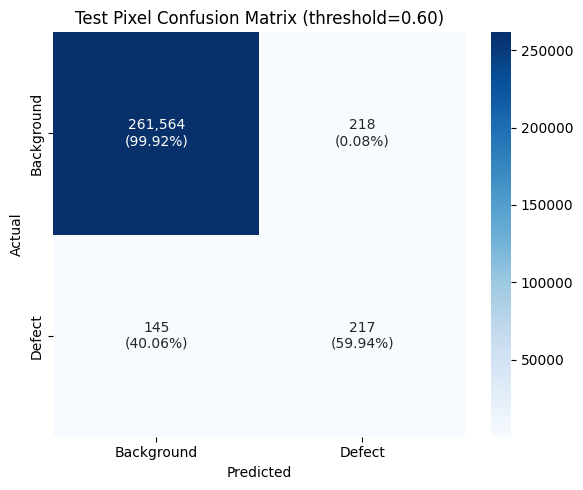

In [14]:
# Test confusion matrix (background/foreground pixels)
tp, fp, fn, tn = split_counts['Test']
cm = np.array([[tn, fp], [fn, tp]], dtype=np.int64)
cm_norm = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)
labels = np.array([[f'{cm[i,j]:,}\n({cm_norm[i,j]:.2%})' for j in range(2)] for i in range(2)])
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=labels, fmt='', cmap='Blues', xticklabels=['Background','Defect'], yticklabels=['Background','Defect'])
plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.title(f'Test Pixel Confusion Matrix (threshold={BEST_THRESHOLD:.2f})')
plt.tight_layout(); plt.savefig(OUTPUT_DIR/'test_confusion_matrix.png', dpi=180, bbox_inches='tight'); plt.show()


## Kaggle step 9 — Inspect predictions

Qualitative inspection catches failure modes that aggregate scores hide: missed tiny defects, merged objects, edge errors, and false positives caused by SEM texture.


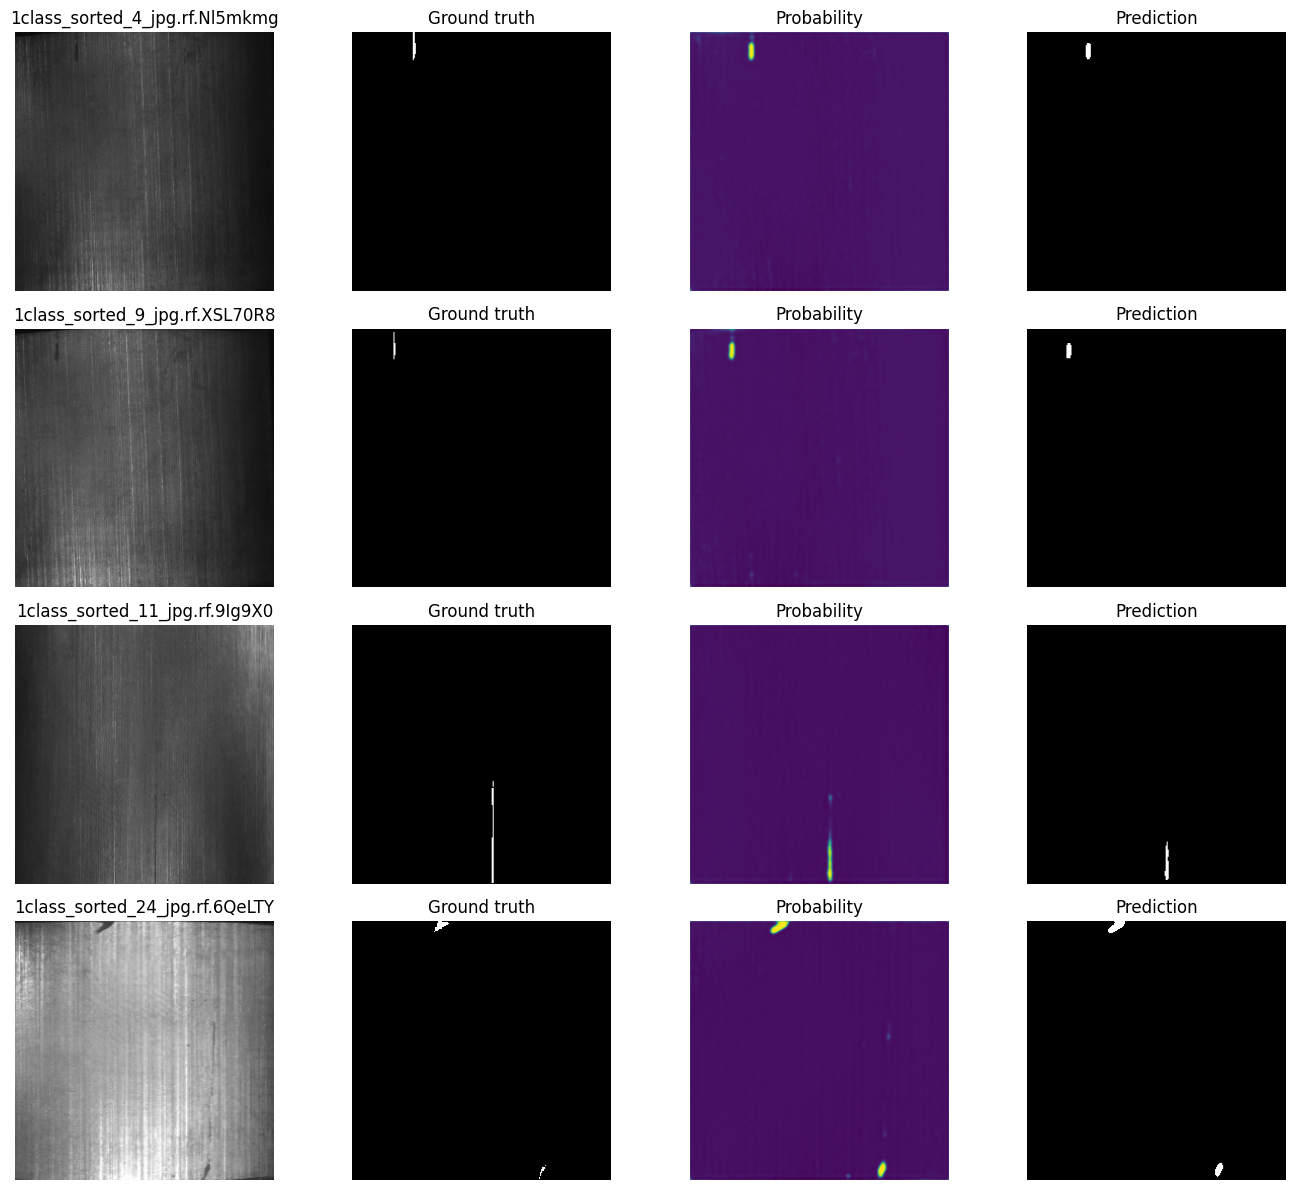

In [15]:
@torch.no_grad()
def show_predictions(dataset, n=5):
    model.eval(); n = min(n, len(dataset)); indices = np.linspace(0, len(dataset)-1, n, dtype=int)
    fig, axes = plt.subplots(n, 4, figsize=(14, 3*n), squeeze=False)
    for row, idx in enumerate(indices):
        image, mask, name = dataset[idx]
        prob = torch.sigmoid(model(image.unsqueeze(0).to(DEVICE)))[0,0].cpu().numpy()
        pred = prob >= BEST_THRESHOLD; img = image.permute(1,2,0).numpy()
        panels = [img, mask[0].numpy(), prob, pred]
        titles = [name[:30], 'Ground truth', 'Probability', 'Prediction']
        cmaps = [None, 'gray', 'viridis', 'gray']
        for col in range(4):
            axes[row,col].imshow(panels[col], cmap=cmaps[col]); axes[row,col].set_title(titles[col]); axes[row,col].axis('off')
    plt.tight_layout(); plt.savefig(OUTPUT_DIR/'test_predictions.png', dpi=180, bbox_inches='tight'); plt.show()

show_predictions(test_ds, n=5)


## If F1 is below 85%

Use evidence from the curves and predictions rather than forcing a number:

1. **First verify masks visually.** Incorrect polygons, missing annotations, or category mistakes cap performance.
2. **Increase resolution** to 384/512 if defects are tiny; lower batch size if needed.
3. **Collect more data.** With about 67 training images, split variance is large. Prefer 5-fold cross-validation for a dependable estimate.
4. **Inspect class balance.** If foreground is extremely sparse, try focal + Dice loss or sample more defect-rich crops.
5. **Tune augmentation carefully.** Remove transforms that create unrealistic SEM textures; add crop-based training if defects occupy few pixels.
6. **Try longer training only if validation is still improving.** If it is overfitting, use a smaller base width (16), stronger regularization, or more data.
7. **Report both F1 and IoU**, and keep the test set untouched until the final evaluation.

The files saved under `/kaggle/working/attention_unet_dataset_1_outputs` can be downloaded from the notebook's **Output** panel.
